# 跨季节苹果树匹配：数据准备（第 1、2 部分）

**当前范围：①配置与数据检查；②标签核对与按行划分。** 本 Notebook 暂不训练模型。
后续模型方案为 Linear Regression baseline + RBF-SVR 主方法，不使用 HOG。

R 是果园行号，N 是有匹配编号的树，U 是未匹配观测。GT 是二维枝条掩膜。
目标是为夏冬同树匹配准备可追溯数据；D 灰度的物理编码未知，因此不输出米制三维坐标。

数据说明参考 [Chen et al., Semantic Segmentation for Partially Occluded Apple Trees Based on Deep Learning](https://arxiv.org/pdf/2010.06879)。
论文的 521 张标注图像与当前本地版本不同，不直接套用论文训练/验证划分。
论文的中心裁剪方式留待第 3 部分实现。


## ① 配置与数据检查

从本项目环境启动 Jupyter，执行 **Restart Kernel and Run All Cells**。
默认数据目录为 `data/TreeID/TreeID`；可在忽略版本控制的 `config/local.json`
或环境变量 `MMA3001_DATA_ROOT` 中改写。
原始图片只读；生成文件写入 `outputs/data_preparation/`。

可使用现有 ECE4179 内核。交互运行只检查计算依赖，`nbformat` / `nbclient` 仅供批量执行工具使用。


In [1]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/experiment.json").is_file() and (p / "src/main.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("请先从项目根目录启动 Jupyter。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.main import get_runtime_versions, load_config, run_data_preparation
from src.utils import index_dataset, read_rgb, read_depth

config = load_config(ROOT)
SYNTHETIC = os.environ.get("MMA3001_SYNTHETIC") == "1"
if SYNTHETIC:
    config.update(output_dir="outputs/synthetic_data_preparation",
                  review_file="outputs/synthetic_data_preparation/pair_review.csv")
    display(Markdown("**CI 合成数据演示：以下数量不是实际果园实验结果。**"))
DATA_ROOT = Path(config["data_root"])
if not DATA_ROOT.is_absolute():
    DATA_ROOT = ROOT / DATA_ROOT
print("Seed:", config["seed"], "| model training: disabled")
print("Python:", sys.executable)
versions = get_runtime_versions()
display(pd.DataFrame({"package": list(versions),
                      "version": [version or "metadata unavailable" for version in versions.values()]}))


Seed: 42 | model training: disabled
Python: D:\anacoda3\envs\MMA3001\python.exe


,package,version
0,numpy,2.5.4
1,pandas,3.0.6
2,Pillow,13.0.0
3,matplotlib,3.11.2


### 1.1 文件名解析、图像质量与内容哈希

以文件名**前缀**解析身份，例如 `R04N01_Winter_D-R04N05_RGB_12-17-20.png`
的当前编号是 `R04N01`，后缀旧编号不覆盖它。
检查 RGB 可读性、尺寸、SHA-256；检查 D 是否为同尺寸 8-bit 灰度或三个相同灰度通道。
缺失或异常 D 会被记录，保留有效 RGB 观测。


In [2]:
index = index_dataset(DATA_ROOT)
overview = index.groupby(["kind", "season"]).agg(
    observations=("tree_id", "size"), valid_rgb=("valid_rgb", "sum"),
    rgb_width=("width", "min"), rgb_height=("height", "min"),
    gt_images=("gt_path", lambda values: values.ne("").sum()))
display(overview)
display(index[["tree_id", "season", "width", "height", "rgb_status", "depth_status",
               "depth_zero_fraction", "gt_status", "gt_width", "gt_height"]].head(8))
print("Observations with corrected / non-time-only suffix:", int(index["special_suffix"].sum()))
print("RGB status:", index["rgb_status"].value_counts().to_dict())
print("D status:", index["depth_status"].value_counts().to_dict())


observations  valid_rgb  rgb_width  rgb_height  gt_images
kind season                                                           
N    Summer           562        562        640         480        562
     Winter           562        562        640         480          0
U    Summer           544        544        640         480          0
     Winter           544        544        640         480          0

,tree_id,season,width,height,rgb_status,depth_status,depth_zero_fraction,gt_status,gt_width,gt_height
0,R01U01,Summer,640,480,ok,ok,0.180114,not_provided,0,0
1,R01U01,Winter,640,480,ok,ok,0.540365,not_provided,0,0
2,R01U02,Summer,640,480,ok,ok,0.029844,not_provided,0,0
3,R01U02,Winter,640,480,ok,ok,0.504479,not_provided,0,0
4,R01U03,Summer,640,480,ok,ok,0.123298,not_provided,0,0
5,R01U03,Winter,640,480,ok,ok,0.548975,not_provided,0,0
6,R01U04,Summer,640,480,ok,ok,0.063363,not_provided,0,0
7,R01U04,Winter,640,480,ok,ok,0.448184,not_provided,0,0


Observations with corrected / non-time-only suffix: 52
RGB status: {'ok': 2212}
D status: {'ok': 2212}


### 1.2 样本检查

RGB 和 D 使用相同像素视野；GT 单独显示，不能把不同尺寸的 GT 直接叠加到原图。
D 的零值比例仅是图像统计量，此处不把灰度映射成距离。


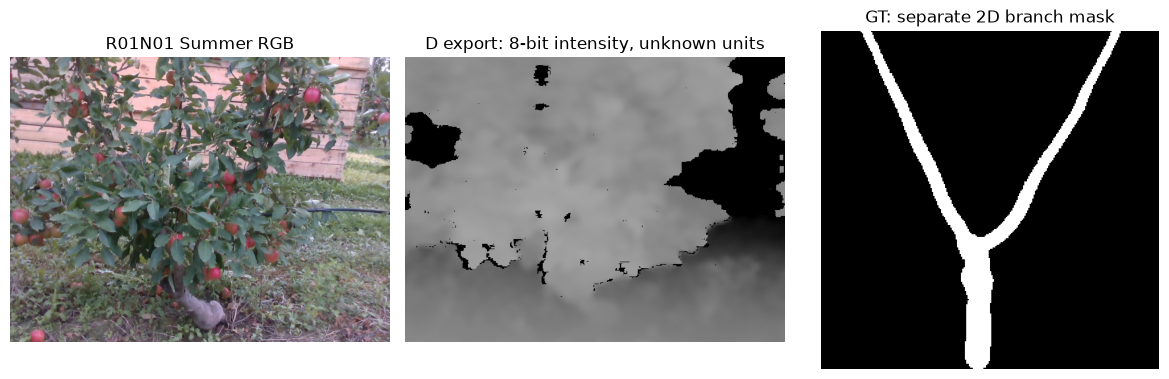

In [3]:
sample = index[index["kind"].eq("N") & index["season"].eq("Summer") & index["valid_rgb"]].iloc[0]
rgb = read_rgb(sample["rgb_path"])
depth, depth_status = read_depth(sample["depth_path"], rgb.shape[:2])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(rgb)
axes[0].set_title(f"{sample['tree_id']} Summer RGB")
if depth is not None:
    axes[1].imshow(depth, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("D export: 8-bit intensity, unknown units")
if sample["gt_path"]:
    from PIL import Image as PILImage
    with PILImage.open(sample["gt_path"]) as gt_image:
        axes[2].imshow(np.asarray(gt_image), cmap="gray", vmin=0, vmax=255)
axes[2].set_title("GT: separate 2D branch mask")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
plt.show()


## ② 标签核对与按行划分

只为 N 建立同 `(R,N)` 的夏冬候选配对。U 不生成正负标签。
先按行划分，再由后续阶段生成训练样本：20 行时为 **12 行训练、4 行验证、4 行测试**。
随机种子为 42；同一行、身份、RGB 路径和完全相同的 RGB 内容不得跨集合。

每行选两对，并将 R04 全部纳入视觉抽查。自动生成的表全部初始化为 `pending`；
只有实际人工检查后才能填写 `confirmed` 或 `rejected`。已有人工记录在重新运行时保留。


In [4]:
result = run_data_preparation(ROOT, config=config, render=True, index=index)
cases = result["cases"]
summary = result["summary"]
display(cases.groupby("split").agg(rows=("row", "nunique"), tree_pairs=("tree_id", "size")))
row_assignment = cases.groupby(["row", "split"]).size().rename("tree_pairs").reset_index()
display(row_assignment)


Part 1: reading image headers, RGB content hashes and D/GT quality...


Part 2: 562 proposed N pairs; U observations stay unlabelled.


{
  "stage": "1_config_and_data_audit__2_label_review_and_row_split",
  "models_trained": false,
  "observations": 2212,
  "valid_rgb_observations": 2212,
  "proposed_n_pairs": 562,
  "eligible_n_pairs": 562,
  "unmatched_u_observations": 1088,
  "review_required": 59,
  "review_pending": 59,
  "review_confirmed": 0,
  "review_rejected": 0,
  "label_status": "filename_based_pending_human_review",
  "split_rows": {
    "test": 4,
    "train": 12,
    "validation": 4
  },
  "split_trees": {
    "test": 133,
    "train": 316,
    "validation": 113
  },
  "leakage_checks_passed": true,
  "seed": 42,
  "depth_metric_scale": "unknown",
  "source_paper": "https://arxiv.org/pdf/2010.06879",
  "split_manifest_sha256": "d9ecb4b908ab848176637220adde13a7e18df52c0ea60bc35d09629c6c26440e"
}


Human review remains pending for 59 required pairs. No human approvals are fabricated.


,rows,tree_pairs
split,,
test,4,133
train,12,316
validation,4,113


,row,split,tree_pairs
0,R01,train,44
1,R02,test,43
2,R03,validation,34
3,R04,train,21
4,R05,validation,34
5,R06,train,32
6,R07,train,32
7,R08,train,22
8,R09,test,34
9,R10,train,29


### 2.1 人工核对表与图册

编辑 `config/pair_review.csv` 的 `human_status` 和 `human_notes`：

- `pending`：尚未核实；
- `confirmed`：人工确认是同一棵树；
- `rejected`：发现错配，填写原因；重新运行后显式排除。

所有 N 配对都可编辑；`required_review=True` 是要求抽查的集合。
图册覆盖全部要求抽查的配对，下面只展示第一页，其余保存在输出目录。


,tree_id,row,required_review,human_status,human_notes
3,R01N04,R01,True,pending,
34,R01N35,R01,True,pending,
62,R02N19,R02,True,pending,
86,R02N43,R02,True,pending,
89,R03N03,R03,True,pending,
110,R03N24,R03,True,pending,
121,R04N01,R04,True,pending,
122,R04N02,R04,True,pending,
123,R04N03,R04,True,pending,
124,R04N04,R04,True,pending,


**要求核对 59 对；仍待人工确认 59 对。**

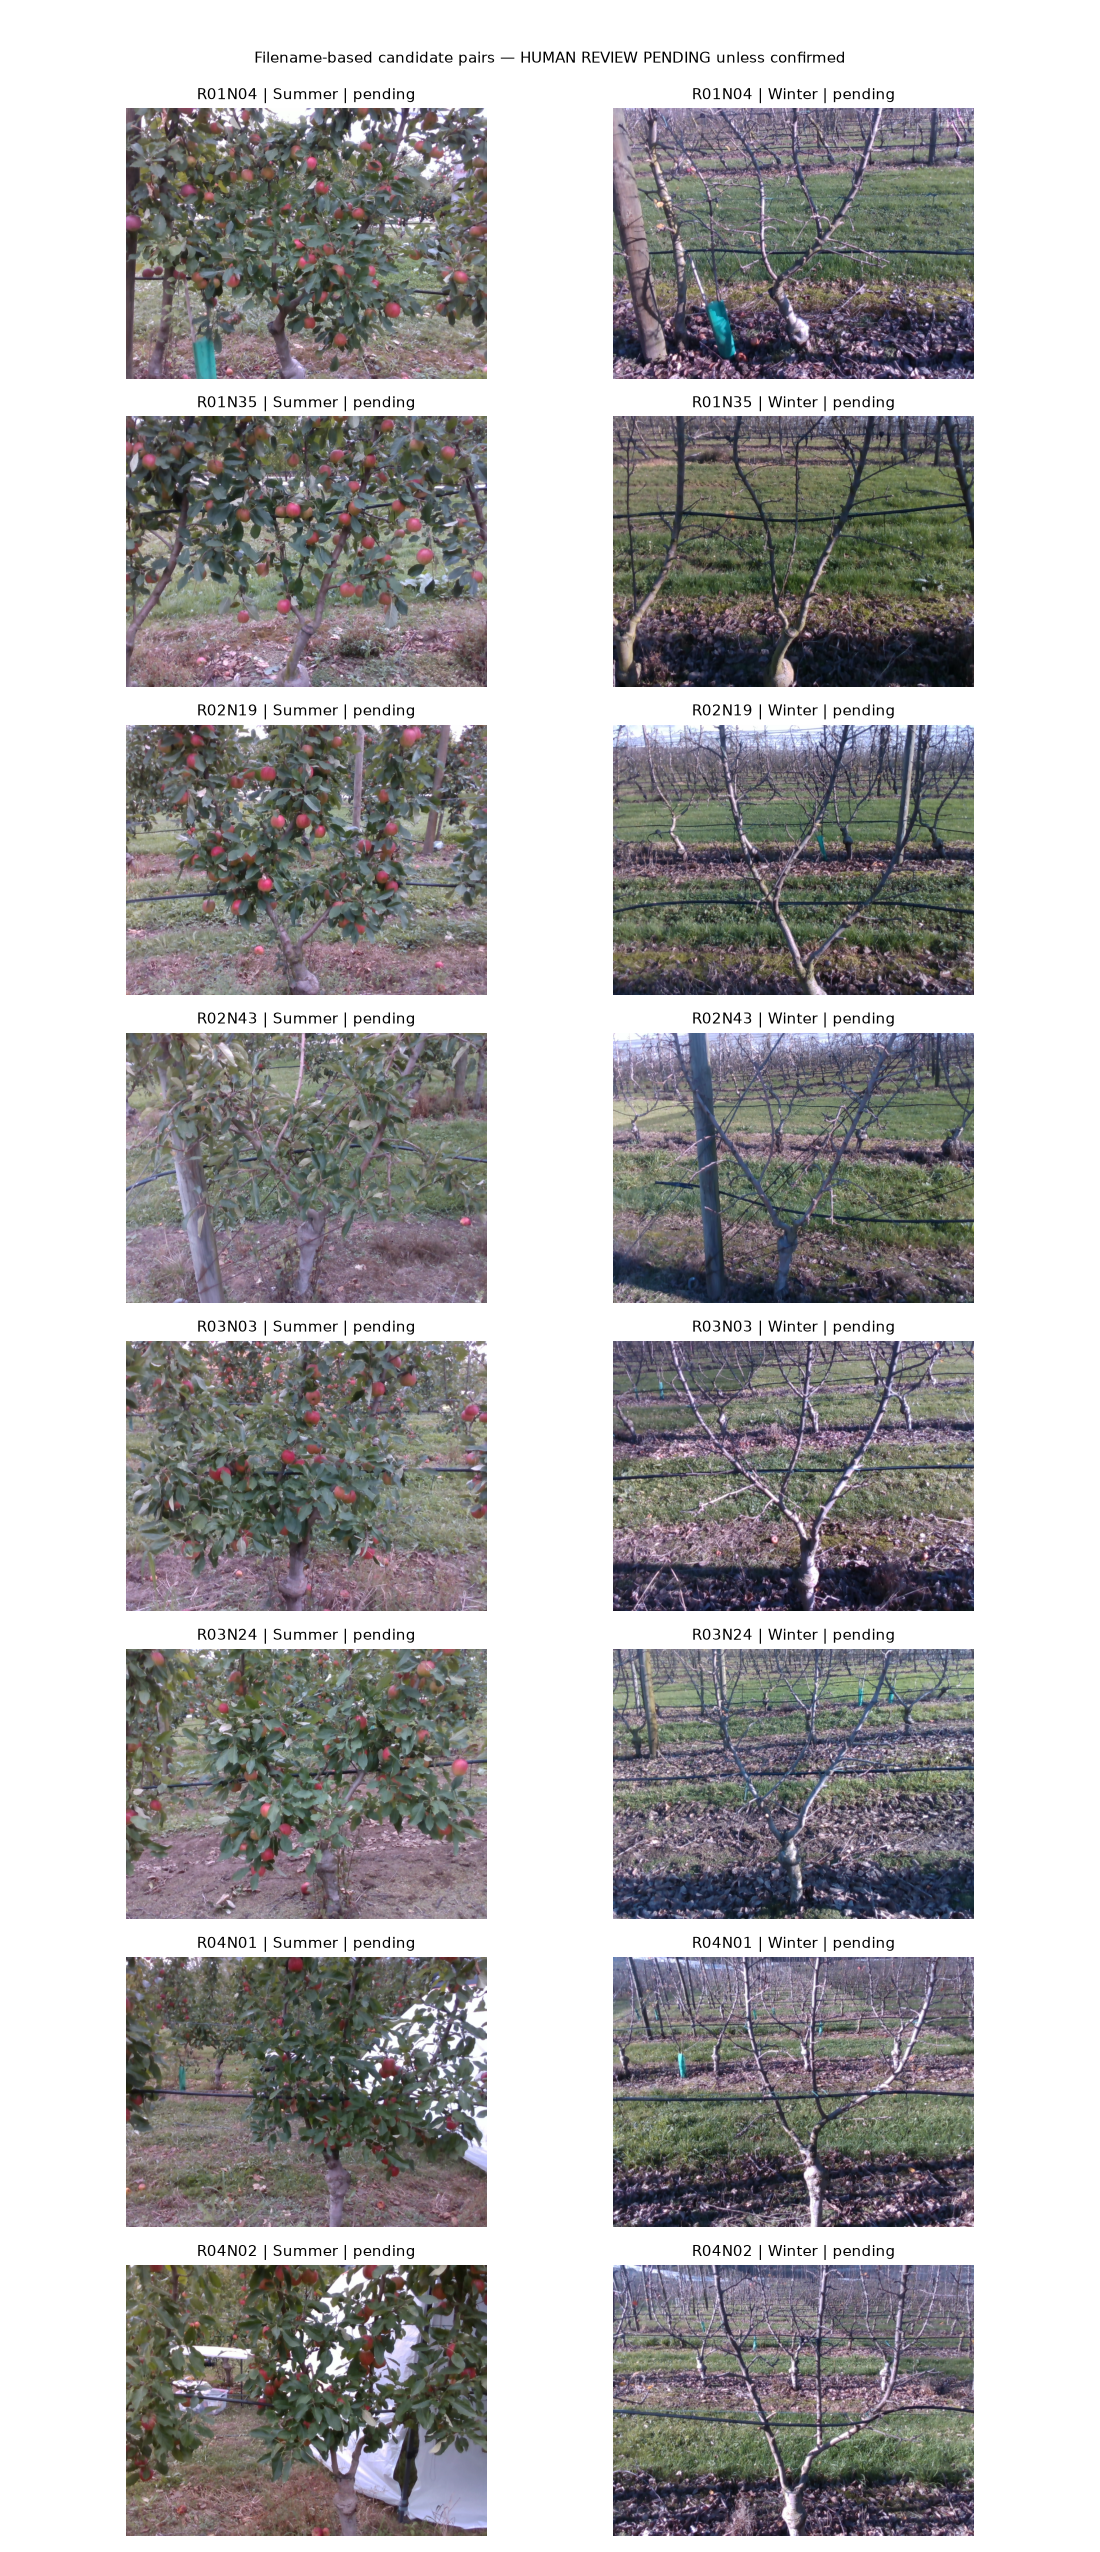

outputs/data_preparation/review_sheets/review_01.png
outputs/data_preparation/review_sheets/review_02.png
outputs/data_preparation/review_sheets/review_03.png
outputs/data_preparation/review_sheets/review_04.png
outputs/data_preparation/review_sheets/review_05.png
outputs/data_preparation/review_sheets/review_06.png
outputs/data_preparation/review_sheets/review_07.png
outputs/data_preparation/review_sheets/review_08.png


In [5]:
review = result["review"]
display(review.loc[review["required_review"],
                   ["tree_id", "row", "required_review", "human_status", "human_notes"]].head(12))
display(Markdown(f"**要求核对 {summary['review_required']} 对；仍待人工确认 {summary['review_pending']} 对。**"))
if result["contact_sheets"]:
    display(DisplayImage(filename=str(result["contact_sheets"][0]), width=820))
for path in result["contact_sheets"]:
    print(path.relative_to(ROOT).as_posix())


### 2.2 泄漏检查、异常与编号索引图

重复的 RGB 内容会单独导出；若其跨越 N 数据的训练/验证/测试集合，流程报错。
U 中的内容重叠仅作审计，不被误当作独立身份。
下图按 R、N 表示编号位置，不是由 GPS 或米制坐标建立的地图。


,split_a,split_b,field,overlap_count,passed
0,train,validation,row,0,True
1,train,validation,tree_id,0,True
2,train,validation,rgb_path,0,True
3,train,validation,rgb_sha256,0,True
4,train,test,row,0,True
5,train,test,tree_id,0,True
6,train,test,rgb_path,0,True
7,train,test,rgb_sha256,0,True
8,validation,test,row,0,True
9,validation,test,tree_id,0,True


,subset,tree_id,reason


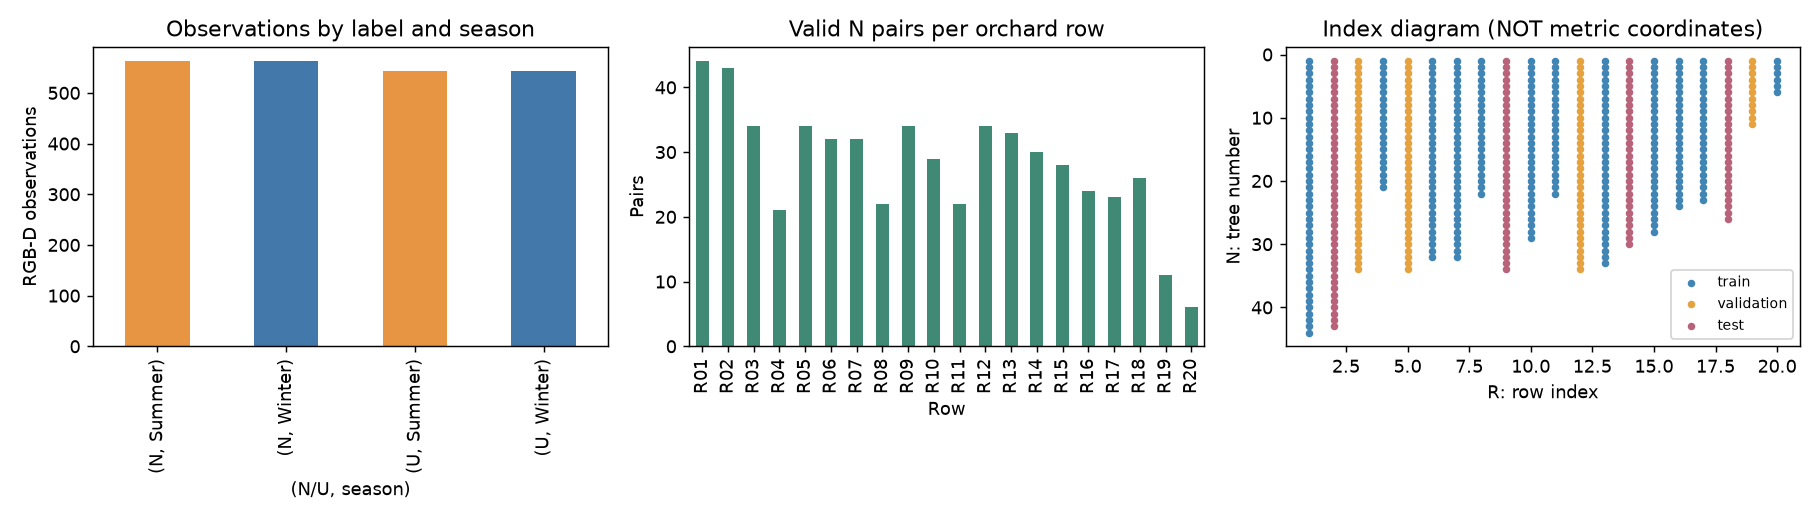

In [6]:
display(result["leakage"])
display(result["exclusions"])
assert result["leakage"]["passed"].all()
assert not summary["models_trained"]
display(DisplayImage(filename=str(result["figures"][0]), width=1100))


### 2.3 可复现输出与当前边界

`outputs/data_preparation/` 包含：

- `observation_index.csv`：观测、文件哈希、D/GT 状态；
- `split_manifest.csv`：固定的身份级分组；
- `train/validation/test_queries.csv` 和对应 `*_gallery.csv`：未来检索输入；
- `quality_issues.csv`、`special_filenames.csv`、`duplicate_rgb_content.csv`、`excluded_n_pairs.csv`；
- `leakage_checks.csv`、`summary.json`、`review_sheets/` 和 `figures/`。

图像路径按项目根目录保存为相对路径，整个项目迁移后仍可解析。
数据划分在人工核对未完成时属于**基于文件名标签的暂定划分**。
第 3–8 部分（特征、数值拟合、Linear Regression、SVR、评估和优化）本轮不执行。


In [7]:
print("Split manifest SHA-256:", summary["split_manifest_sha256"])
print("Label status:", summary["label_status"])
print("Leakage checks passed:", summary["leakage_checks_passed"])
print("Models trained:", summary["models_trained"])
print("Generated outputs:", result["output_dir"].relative_to(ROOT).as_posix())


Split manifest SHA-256: d9ecb4b908ab848176637220adde13a7e18df52c0ea60bc35d09629c6c26440e
Label status: filename_based_pending_human_review
Leakage checks passed: True
Models trained: False
Generated outputs: outputs/data_preparation


## 数据来源与 AI 使用

- 数据：用户提供的 TreeID；原始图片未改写，数据不随代码自动上传。
- 来源论文：[Chen et al. (2020)](https://arxiv.org/pdf/2010.06879)，用于解释数据背景和后续预处理依据。
- R/N/U 含义来自用户说明和目录中的 `FANK_Sat.png`。
- AI 协助设计并实现读取、审计、划分、图册、Notebook 和测试；验证方式见 `doc/ai_usage.md`。
- 人工配对确认由实际审阅者填写，程序和 AI 不自动伪造人工确认。
